# Wielowymiarowe ujęcie zróżnicowania poziomu jakości życia w województwach w Polsce
---
## Projekt Zaliczeniowy - Statystyczna Analiza Danych

W pracy będziemy badać poziom jakości życia w polskich województwach. Pod uwage zostały wzięte zmienne reprezentujące dane sfery życia: samorząd, rynek pracy, warunki mieszkaniowe, społeczeńswto, bezpieczeństwo, środowisko, sport i rekreacja, przedsiebiorczość, i warunki materialne.

Analiza jest inspirowana publikacją naukową pt.: "Wielowymiarowe ujęcie zróżnicowania poziomu jakości życia w województwach w Polsce" autorstwa Elżbiety Roszko-Wójtowicz i Marii M. Grzelak z Uniwersytetu Łódzkiego.

Celem pracy jest zbadanie województw pod kątem atrakcyjności dla przecętnego mieszkańca, wyodrębnienie najlepszych i najgorszych obszarów pod tym kątem, porównanie wyników z wyżej wymienioną analizą.

In [45]:
import os
import pandas as pd
import numpy as np
from IPython.display import HTML, display
import seaborn as sns
import matplotlib.pyplot as plt

def display_df(df):
    tabela_styl = (df.style.format(precision=2).set_table_styles([
        {'selector': '', 'props': [('border', '1px solid #d3d3d3'),('min-width', 'max-content')]},
        {'selector': 'th', 'props': [('border', '1px solid #d3d3d3'),('text-align', 'left')]},
        {'selector': 'td', 'props': [('border', '1px solid #d3d3d3')]}
    ]))
    display(HTML(f"<div style='overflow-x: auto; width: 100%;'>{tabela_styl.to_html()}</div>"))

---

## 0. Przygotowanie danych

In [46]:
catalog = "./data"
csv_files = []
var_name_list = []

with os.scandir(catalog) as entries:
    for entry in entries:
        if entry.is_file() and entry.name.endswith(".csv"):
            csv_files.append(entry.path)

df_2015 = None
df_2024 = None
i = 1

for file in csv_files:
    var_name = os.path.basename(file).replace(".csv", "")
    var_name_list.append(var_name)
    df = pd.read_csv(file, sep=";")

    column_2015 = [c for c in df.columns if '2015' in c][0]
    column_2024 = [c for c in df.columns if '2024' in c][0]
    df[column_2015] = pd.to_numeric(df[column_2015].astype(str).str.replace(',', '.').str.strip(), errors='coerce')
    df[column_2024] = pd.to_numeric(df[column_2024].astype(str).str.replace(',', '.').str.strip(), errors='coerce')

    temp_2015 = pd.DataFrame()
    temp_2024 = pd.DataFrame()

    temp_2015['Nazwa'] = df['Nazwa'].copy()
    temp_2015[f'X{i} {var_name}'] = df[column_2015].copy()

    temp_2024['Nazwa'] = df['Nazwa'].copy()
    temp_2024[f'X{i} {var_name}'] = df[column_2024].copy()

    if df_2015 is None:
        df_2015 = temp_2015
        df_2024 = temp_2024
    else:
        df_2015 = pd.merge(df_2015, temp_2015, on='Nazwa')
        df_2024 = pd.merge(df_2024, temp_2024, on='Nazwa')

    i += 1

df_2015 = df_2015.set_index('Nazwa')[:-1]
df_2024 = df_2024.set_index('Nazwa')[:-1]

Wynik: dane są przygotowane w osobnych ramkach danych z względu na aktualność danych. W publikacji która stanowi nasz odnośnik wykorzystywany jest: "Wskaźnik wykrywalności przestepstw kryminalnych". My wzieliśmy pod uwagę przestepców, ponieważ GUS nie udostepnia już wskaźnika o takiej nazwie.

---

## 1. Wprowadzenie - dane

$X1$ - Emisja zanieczyszczeń pyłowych na 1 km2 **[emisja_pylkow]**

$X2$ - Gęstość zaludnienia (os./km2) **[gestosc_zaludnienia]**

$X3$ - Nakłady inwestycyjne na jednego mieszkańca (zł) **[naklady_inwestycyjne]**

$X4$ - Liczba zarejestrowanych podmiotów gospodarczych w przeliczeniu na 1000 mieszka **[podmioty_gospodarcze]**

$X5$ - Powierzchnia mieszkań oddanych do użytku w m2 na jednego mieszkańca (m2/os.) **[powierzchnia_mieszkaniowa]**

$X6$ - Wskaźnik wykrywalności sprawców przestępstw kryminalnych (%) **[przestepstwa]**

$X7$ - Średnie wynagrodzenie brutto (zł) **[srednie_wynagrodzenie]**

$X8$ - Liczby bezrobotnych w liczbie osób w wieku produkcyjnym (%) **[stopa_bezrobocia]**

$X9$ - Udział parków, zieleńców i terenów zieleni osiedlowej w powierzchni ogółem (%) **[udzial_zieleni_w_powierzchni]**

---

## 2. Statystyka Opisowa

### 2.1 Dodanie funkcji liczącej wszystkie statystyki

Podstawowe miary statystyki opisowej dla każdej zmiennej diagnostycznej:

$\bar{x}$ – średnia arytmetyczna

$M_e$ – mediana

$S_x$ – odchylenie standardowe z próby

$V_s$ – klasyczny współczynnik zmienności

$K$ – kurtoza

$A_s$ – współczynnik asymetrii / skośność

$MIN$ – wartość minimalna wraz z nazwą województwa

$MAX$ – wartość maksymalna wraz z nazwą województwa

Nie będziemy sprawdzać czy istnieją braki w danych (możemy od razu zauważyć, że takowe nie występują), oraz rozważać wartości odstających ze względu na charakter danych.

In [47]:
def oblicz_statystyki_opisowe(df, rok):
    stat = []
    for col in df.columns:
        s = df[col]
        stat.append({
            'Zmienna': col,
            'Rok': rok,
            'Średnia': s.mean(),
            'Mediana': s.median(),
            'Odchylenie standardowe': s.std(),
            'Wspołczynnik zmienności': s.std()/s.mean() if s.mean()!=0 else 0,
            'Kurtoza': s.kurtosis(),
            'Skośność': s.skew(),
            'Max': f"{s.idxmax()}: {s.max()}",
            'Min': f"{s.idxmin()}: {s.min()}"
        })
    return pd.DataFrame(stat)

tabela1 = oblicz_statystyki_opisowe(df_2015, '2015')
tabela2 = oblicz_statystyki_opisowe(df_2024, '2024')

tabela = pd.concat([tabela1, tabela2], ignore_index=True)
tabela = tabela.sort_values(by=['Zmienna', 'Rok']).reset_index(drop=True)
tabela = tabela.set_index(['Zmienna', 'Rok'])

display_df(tabela)

### 2.2 Analiza statystyk opisowych

In [48]:
display_df(tabela.loc[['X1 emisja_pylkow']])

Patrząc na średnią czy medianę dla obu lat, wartość tego wskaźnika jest niska. Widzimy spadek o 0.1 w średniej i 0.08 w medianie. Emisja pyłków dla poszczegółnych województw mocno sie waha. Możemy to stwierdzić po dużej wartości odchylenia standardowego, jak i różnicy między maksymalną i minimalną wartością. Jeśli chodzi o województwa dla których te wyniki są osiągane, śląskie i warmińsko-mazurskie, to te obszary nie stanowią zaskoczenia. Wpływa na to przemysł, gęste zaludnie, ogrzewanie węglowe i ukształtowania terenu na Śląsku, oraz jeśli chodzi o Mazury - duża ilość jezior i zalesienie sprzyjają czystszemu powietrzu. Współczynnik zmienności mówi nam również o ogromnym zróznicowaniu województw pod kątem zanieczyszczeń pyłowych (ponad 100% w 2015, w 2024 ta wartośc zmalała, nadal jednak sięga prawie 100%). Obserwujemy także skośność prawostronną. Oznacza to, że w większości województw emisja pyłków jest na poziomie ponieżej średniej. Widzimy także, że często występują wartości odstające (reprezentuje je np. woj. Śląskie), ale również duża część odczytów koncentruję się wokół średniej. Na przestrzeni tych 9 lat możemy także obserwować zmiejszenie się dysproporcji zanieczyszcenia powietrza województwami między. Wynika to prawdopodnie z rosnącej świadomości ekologicznej jak i idących za tym przepisów prawnych.

In [49]:
display_df(tabela.loc[['X2 gestosc_zaludnienia']])

Widzimy, ze wartość tego wskaźnika osiąga warości umiarkowane, jeśli patrzymy na średnią czy medianę. Gęstość zaludnienia mocno się jednak waha między województwami (odchylenie standardowe stanowy przeszło połowę średniej, wysoki współczynnik zmienności, który nie zmienił się na przestrzeni lat). Po raz kolejny mamy tu do czynienia ze skośnoscią prawostronną. Kurtoza osiąga niższe warości dla analizowanego wskaźnika, lecz nadal jest wysoka, zwłaszcza w 2015. Świadczy to o grubych ogonach i istnieniu outlinerów. Przykładem takiego outlinera jest województwo Śląskie z ok. 3 razy większą gęstością zaludnienia w porównaniu do średniej. Naprzeciw wychodzi woj. podlaskie (2015) i woj. warmińsko-mazurskie (2024) z wynikiem o około połowę mniejszym od średniej. Oba te przypadki wpływają na wartość kurtozy i skośności. Te różnice wyniką m.in z wielkości województw, urbanizacji, ukształtowania terenu.

In [50]:
display_df(tabela.loc[['X3 naklady_inwestycyjne']])

Jeśli chodzi o nakłady inwestycyjne na 1 mieszkańca średnio prawie 7000 zł (2015) i 11 000zł (2024), to dobry wynik. Rok 2015 jest rokiem w którym możemy zaobserwować mniejsze dysproporcje niż w 2024. Współczynnik zmienności mówi nam o małej lub umiarkowanej zmienności, lecz widzimy wzrost wartości kurtozy i skośności w rozważanych okresach. Potwierdza to również różnica między wartością maksymalną i minimalną (w 2015 około 6 tys., w 2024 około 13 tys.). Województwo mazowieckie utrzymało swoją pozycję jako lidera w tej kategorii (co jest naturalną konsekwencją koncentracji kapitału w regionie stołecznym).

In [51]:
display_df(tabela.loc[['X4 podmioty_gospodarcze']])

Zarejestrowane podmioty gospodarcze w przeliczeniu na 1000 mieszkańców reprezentują w naszej analizie stan przedsiębiorczości Polaków. Patrząc na tabele możemy dostrzec, że kształtuje się na umiarkowanym poziomie. Niskie odchylenie standarodowe, współczynnik zmienności, mała różnica między maksumum i minimum oraz ujemna kurtoza wskazują na spłaszczony rozkład wyników i brak drastycznych wartości odstających między regionami. Po raz kolejny najwększy wynik osiąga mazowieckie, na ostatnim miejscu plasuje się podkarpackie.

In [52]:
display_df(tabela.loc[['X5 powierzchnia_mieszkaniowa']])

Jeśli chodzi o Polskę, średnia powierzchnia mieszkaniowa wynosząca blisko 30, to przeciętny wynik. W porówaniu do standardu europejskiego (35 - 40 ) wynik ten klasuję się poniżej średniej. Po wartości pozostałych wskażników, możemy stwierdzić, że nie ma istotnych różnic między województwami. Mamy małe odchylenie standarowe, niski współczynnik zmieności, mało outlinerów, wartości naszego wskażnika są raczej skoncentrowane, z tendencją bycia wyższymi od średniej. Biorąc pod uwage maksymalną i minimalną wartość, ona województwa zachowały swoje pozycje.

In [53]:
display_df(tabela.loc[['X6 przestepstwa']])

Wkaźnik wykrywalności sprawców przestępstw kryminalnych wynoszący średnio około 70% w obu latach to dobry wynik. Nie mamy tu do czynienia z wysokim zróżnicowaniem między województwami, mało wartości odstających, są one raczej skoncentrowane. Widzimy tendencję wartości wskaźnika do bycia zbliżonym do średniej w wielu województwach. Lekka skośność lewostronna, ale rozkła jest zbliżony do normalnego w obu latach (zwłaszcza w 2024). Najbezpiecznijsze województwa to świętokrzystkie i małopolskie. Po drugiej stronie znajduje się mazowieckie.

In [54]:
display_df(tabela.loc[['X7 srednie_wynagrodzenie']])

Średnie wynagrodzenie brutto wzrosło w ciągu 9 lat ponad dwukrotnie, co ma związek m.in. z inflacją oraz wzrostem kosztów utrzymania. Zróżnicowanie między województwami w ramach tego wskaźnika jest stosunkowo małe. Występują jednak wartości odstające, ltóre wpływają na wynik kurtozy w 2015 roku. W tym okresie możemy także zaobserwować większą skośność prwostronną niż w 2024 roku. Możemy z tego wywnioskować, że pomimo ogólnego wzrostu płac i kosztów życia, dysproporcje płacowe między województwami powoli maleją.

In [55]:
display_df(tabela.loc[['X8 stopa_bezrobocia']])

Widzimy, że stopa bezrobocia zmalała prawie trzykrotnie w okresie 2015 - 2024. Odchylenie standardowe tego wskaźnika także zmalało, choć współczynnik zmienności nieznacznie wzrósł. Wynosi on jednak 24 - 25%, co wciąż pozwala uznać populację za stosunkowo jednorodną pod tym względem. Zmiana wartości skośności pokazuje ewolucję rozkładu względem średniej (w 2015 r. występujeła lekka skośność prawostronna, w 2024 r. rozkład jest bardziej symetryczny). Ponieważ wartości skośności w obu latach są bliskie zera, układ można uznać za zbliżony do normalnego.

In [56]:
display_df(tabela.loc[['X9 udzial_zieleni_w_powierzchni']])

Średni udział zieleni w powierzchni ogółem nieznacznie się zmienił w ciągu analizowanyh lat. Stabilność tego wskaźnika świadczy o stałym utrzymywaniu miejskiej infrastruktury zielonej w regionach. Najwyższą wartość wskaźnika odnotowujemy w województwie śląskim (0,8% w 2015 r. oraz 0,7% w 2024 r.). Wynika to z faktu, że Śląsk jest regionem o najwyższym stopniu urbanizacji i zagęszczenia miast, co wiąże się z zagęszczeniem osiedli oraz rozbudowaną siecią parków miejskich i zieleńców. Najmniejsza wartość przypada niezmiennie lubelskiemu, co wiąże się z jego silnie rolniczym charakterem (duży udział gruntów ornych kosztem zwartych kompleksów leśnych). Na uwagę zasługuje wysoka kurtoza, świadcząca o obecności wartości odstających, oraz znaczna niejednorodność populacji (współczynnik zmienności na poziomie 63–83%).

### 2.3 Analiza macierzy korelacji

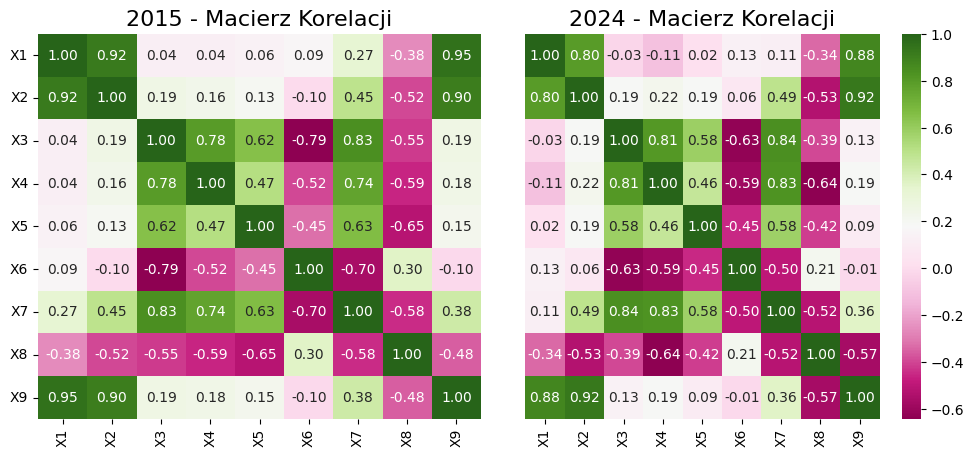

In [57]:
corr_2015 = df_2015.corr()
corr_2024 = df_2024.corr()

fig, axes = plt.subplots(ncols = 2,  figsize=(12, 5))
ax1, ax2 = axes

sns.heatmap(corr_2015, annot=True, fmt=".2f", cmap="PiYG", ax=ax1, cbar=False)
ax1.set_title('2015 - Macierz Korelacji', fontsize=16)
ax1.set_xticklabels([label[:2] for label in corr_2015])
ax1.set_yticklabels([label[:2] for label in corr_2015])

sns.heatmap(corr_2024, annot=True, fmt=".2f", cmap="PiYG", ax=ax2, yticklabels=False)
ax2.set_title('2024 - Macierz Korelacji', fontsize=16)
ax2.set_xticklabels([label[:2] for label in corr_2024])

plt.subplots_adjust(wspace=0.1)

plt.show()

Wstępna analiza macierzy korelacji pokazuje, jak powiązane są ze sobą wybrane wskaźniki jakości życia oraz czy na przestrzeni lat (2015 vs. 2024) te relacje pozostały równe. Zauważalna jest bardzo silna dodatnia korelacja pomiędzy emisją pyłów ($X1$), gęstością zaludnienia ($X2$) oraz udziałem terenów zielonych ($X9$). Współczynniki sięgają tutaj wartości od 0,80 do 0,95. Regiony gęściej zaludnione to obszary wysoce zurbanizowane. Z jednej strony generują większe zanieczyszczenia przemysłowo-komunikacyjne ($X1$), a z drugiej posiadają największy odsetek skatalogowanych zieleńców i parków miejskich ($X9$). Relacja ta pozostała niemal niezmienna w obu badanych latach. Wskaźniki ekonomiczne wykazują silną, logiczną spójność. Wysokie nakłady inwestycyjne ($X3$), przedsiębiorczość mieszkańców ($X4$) oraz wysokie wynagrodzenia ($X7$) wyraźnie idą w parze. Zmienne te sprzyjają rynkowi mieszkalnemu ($X5$ wykazuje dodatnie korelacje z inwestycjami i płacami) oraz wyraźnie ograniczają bezrobocie ($X8$ ma ujemne korelacje z całym blokiem gospodarczym).

Wskaźnik wykrywalności przestępstw ($X6$) koreluje ujemnie z poziomem zamożności i inwestycji . Wynika to ze specyfiki regionalnej – w dużych, bogatych aglomeracjach rejestruje się więcej anonimowych przestępstw trudniejszych do natychmiastowego wykrycia niż w mniejszych, spokojniejszych ośrodkach. Struktura powiązań między cechami w 2015 roku i 2024 roku jest bardzo zbliżona. Oznacza to, że mechanizmy kształtujące jakość życia w województwach mają charakter stabilny na przestrzeni ostatnich 10 lat.

---

## 3. Porządkowanie liniowe

### 3.1 Stymulanty i Destymulanty

| $X$ | Zmienna | Kategoria | Kierunek Wpływu |
| --- | --- | --- | --- |
| $X1$ | emisja_pylow | Środowisko | Destymulanta |
| $X2$ | gestosc_zaludnienia | Społeczeństwo | Stymulanta |
| $X3$ | naklady_inwestycyjne | Samorząd | Stymulanta |
| $X4$ | podmioty_gospodarcze | Przedsiębiorczość | Stymulanta |
| $X5$ | powierzchnia_mieszkaniowa | Warunki mieszkaniowe | Stymulanta |
| $X6$ | przestepstwa | Bezpieczeństwo | Stymulanta |
| $X7$ | srednie_wynagrodzenie | Warunki materialne | Stymulanta |
| $X8$ | stopa_bezrobocia | Rynek pracy | Destymulanta |
| $X9$ | udzial_zieleni_w_powierzchni | Sport i Rekreacja | Stymulanta |


#### 3.2 Metoda Hellwiga (dla 2015 i 2024)

In [58]:
def utworz_miernik_hellwiga(df):
    # 1. Zmianna destymulant na stymulanty
    temp = df.copy()
    for col in temp.columns:
        if col in ['emisja_pylow', 'stopa_bezrobocia']:
            temp[col] = temp[col]*(-1)

    # 2. Standaryzacja danych
    for col in df.columns:
       temp[col] = (temp[col] - temp[col].mean())/temp[col].std()

    # 3. Obliczenie najlepszego obiektu (wzorca)
    wzorzec = {}
    for col in temp.columns:
        wzorzec[col] = temp[col].max()

    # 4. Obliczenie odległości poszczególnych obiektów od wzorca
    p0 = pd.Series(wzorzec)
    d = np.sqrt(((temp-p0)**2).sum(axis=1))

    # 5. Stworzenie odległości “możliwie dalekiej”
    d0 = d.mean() + 2*d.std()

    # 6. Wyznaczenie wartości miary dla każdego obiektu
    s = 1 - d/d0

    ranking_hellwig = pd.DataFrame(
        {
        'Nazwa': s.index,
        'Miernik_Hellwiga': s.values
        })

    ranking_hellwig = ranking_hellwig.sort_values(by='Miernik_Hellwiga', ascending=False).reset_index(drop=True)
    ranking_hellwig['Pozycja'] = range(1, len(ranking_hellwig)+1)
    return ranking_hellwig

r_2015 = utworz_miernik_hellwiga(df_2015)
r_2024 = utworz_miernik_hellwiga(df_2024)

tabela = pd.merge(r_2015, r_2024, on='Nazwa', suffixes=('_2015', '_2024'))
tabela['Zmiana pozycji'] = tabela['Pozycja_2015'] - tabela['Pozycja_2024']
tabela = tabela.sort_values(by='Pozycja_2024').reset_index(drop=True)

display_df(tabela)

,Nazwa,Miernik_Hellwiga_2015,Pozycja_2015,Miernik_Hellwiga_2024,Pozycja_2024,Zmiana pozycji
0,ŚLĄSKIE,0.48,1,0.45,1,0
1,MAZOWIECKIE,0.28,3,0.35,2,1
2,MAŁOPOLSKIE,0.26,4,0.32,3,1
3,DOLNOŚLĄSKIE,0.30,2,0.28,4,-2
4,POMORSKIE,0.22,6,0.23,5,1
5,OPOLSKIE,0.25,5,0.23,6,-1
6,ZACHODNIOPOMORSKIE,0.21,9,0.21,7,2
7,ŁÓDZKIE,0.21,8,0.20,8,0
8,WIELKOPOLSKIE,0.21,7,0.19,9,-2
9,KUJAWSKO-POMORSKIE,0.17,10,0.17,10,0


Zastosowanie metody Hellwiga pozwoliło sprowadzić 9 zmiennych diagnostycznych do jednego syntetycznego wskaźnika jakości życia, przyjmującego wartości z przedziału $[0, 1]$. Im wyższa wartość miernika, tym dane województwo znajduje się bliżej hipotetycznego, idealnego wzorca rozwoju.

Zestawienie wyników dla lat 2015 i 2024 pozwala podzielić województwa na wyraźne grupy oraz zaobserwować stabilność i dynamikę zachodzących zmian:

- Pozycje czołową w obu badanych latach utrzymało województwo śląskie. Wysoki wynik tego regionu wynika przede wszystkim z silnej koncentracji infrastruktury miejskiej, dużej gęstości zaludnienia oraz znacznego udziału terenów zieleni urządzonej, co w modelu wzorcowym mocno przybliża go do wartości maksymalnych. Województwa mazowieckie  oraz małopolskie  odnotowały największy progres wartości miernika. Regiony te dynamicznie nadrabiają dystans do lidera, opierając swój rozwój na wysokich zarobkach, intensywnym budownictwie mieszkaniowym i napływie inwestycji. Wojewódzctwo dolnośląskie zanotowało spadek co jednak nie oznacza pogarszającymi się warunkami życia, jedynie polepszeniem wcześniej wymienionych regionów.
- Województwa zajmujące pozycje od 5. do 11. charakteryzują się bardzo wyrównanymi i stabilnymi w czasie wartościami miernika. Warto odnotować awans województwa zachodniopomorskiego o dwa miejsca w górę oraz lekki spadek wielkopolskiego.
- Ostatnie miejsca składają się z wojewodzctw: świętokrzyskie, podlaskie, lubelskie, podkarpackie oraz zamykające tablice warmińsko-mazurskie. Pomimo korzystnych parametrów środowiskowych, niższy poziom płac, mniejsze nakłady inwestycyjne i słabsza dynamika budownictwa mieszkaniowego przełożyły się na niskie wartości syntetyczne.

Mimo upływu 9 lat generalny układ rankingu cechuje się dużą powtarzalnością. Aż 6 województw nie zmieniło swojej pozycji, a większość pozostałych przesunęła się zaledwie o miejsce czy dwa.

### 3.3 Metoda sum standaryzowanych (dla 2015 i 2024)

In [ ]:
def utworz_miernik_sum(df):

    temp = df.copy()

    # 1. i 2. Zamiana destymulant na stymulanty
    for col in temp.columns:
        if col in ['emisja_pylow', 'stopa_bezrobocia']:
            temp[col] = temp[col]*(-1)

    # 3. Standaryzacja danych
    norm = (temp - temp.mean()) / temp.std()

    # 4. Budowa syntetycznej miary
    s1 = norm.sum(axis=1)

    # 5. Standaryzacja wartości uzyskanych w poprzednim kroku
    s2 = (s1 - s1.mean()) / s1.std()

    # 6. Utworzenie rankingu i posortowanie obiektów
    ranking = pd.DataFrame({
        'Nazwa': s2.index,
        'Miernik_s2': s2.values
    })

    ranking = ranking.sort_values(by='Miernik_s2', ascending=False).reset_index(drop=True)
    ranking['Pozycja'] = range(1, len(ranking) + 1)
    return ranking

ranking_bezwzorcowy_2015 = utworz_miernik_sum(df_2015)
ranking_bezwzorcowy_2024 = utworz_miernik_sum(df_2024)

tabela = pd.merge(ranking_bezwzorcowy_2015, ranking_bezwzorcowy_2024, on='Nazwa', suffixes=('_2015', '_2024'))

tabela['Zmiana pozycji'] = (tabela['Pozycja_2015'] - tabela['Pozycja_2024'])
tabela = tabela.sort_values(by='Pozycja_2024').reset_index(drop=True)

display_df(tabela)

Województwo śląskie oraz województwo mazowieckie zajmują niezmiennie dwa pierwsze miejsca w rankingu. Ich wyniki znacząco przewyższają resztę kraju (ponad 2 odchylenia standardowe powyżej średniej), co potwierdza ich dominującą pozycję gospodarczą i infrastrukturalną. Województwo małopolskie odnotowało spektakularny awans o 3 pozycje (z miejsca 6. na 3.), zwiększając wartość miernika z poziomu bliskiego średniej do wyraźnie dodatniego wyniku. Kosztem Małopolski na 4. pozycję osunęło się województwo dolnośląskie.Wyraźną poprawę pozycji odnotowało województwo pomorskie. Zauważalny jest także awans województwa podlaskiego, które dzięki poprawie wskaźników cząstkowych zbliżyło się do średniej krajowej . Spadki w środkowej części tabeli dotknęły opolskie , zachodniopomorskie, świętokrzyskie oraz lubuskie. Na dole rankingu sytuacja pozostaje trwała: tabele zamykają podkarpackie oraz warmińsko-mazurskie.

Metoda bezwzorcowa wykazała nieco większą dynamikę przetasowań niż metoda Hellwiga. Aż 10 z 16 województw zmieniło swoje pozycje (w tym awanse Małopolski, Pomorza i Podlasia o 3 miejsca). Brak sztywnego punktu odniesienia do jednego wzorca sprawia, że względne różnice między regionami są mocniej uwypuklone. Niezależnie od zastosowanej techniki, bieguny jakości życia w Polsce pozostają identyczne. Na podiumie jest Śląsk, Mazowsze i Małopolska, podczas gdy tabele zamykają Podkarpacie i Warmia z Mazurami.

---

## 4. Analiza skupień

### 4.1 Grupowanie podziałowe - metoda k-medoid

Dzięki powyższej analizie możemy zauważyć, że istnieją województwa, które można określić jako wartości odstające. Z tego względu zastosujemy metodę k-medoid.

Ponieważ funkcja *KMedoids* z pakietu *sklearn_extra.cluster* wymaga kompilatora C++ podczas instalacji, co może być problematyczne przy kompilacji projektu, zdecydowaliśmy się napisać klasę która będzie zastępować potrzebną funkcję.

In [ ]:
# class KMedoids:

#   def __init__(self, n_clusters=3, max_iter=300, random_state=None):
#     self.n_clusters = n_clusters
#     self.max_iter = max_iter
#     self.random_state = random_state

#   def fit(self, X):
#     np.random.seed(self.random_state)
#     n_samples = X.shape[0]

#     medoid_indices = np.random.choice(n_samples, self.n_clusters, replace=False)
#     self.medoids_ = X[medoid_indices]

#     for _ in range(self.max_iter):
#       # odległości euklidesowe
#       distances = np.linalg.norm(
#           X[:, np.newaxis, :] - self.medoids_[np.newaxis, :, :], axis=2
#       )
#       labels = np.argmin(distances, axis=1)

#       new_medoid_indices = np.zeros(self.n_clusters, dtype=int)

#       for k in range(self.n_clusters):
#         cluster_idx = np.where(labels == k)[0]

#         if len(cluster_idx) == 0:
#           new_medoid_indices[k] = medoid_indices[k]
#           continue

#         cluster_data = X[cluster_idx]

#         pairwise_dist = np.linalg.norm(
#             cluster_data[:, np.newaxis, :] - cluster_data[np.newaxis, :, :],
#             axis=2,
#         )
#         sum_dist = np.sum(pairwise_dist, axis=1)

#         best_idx_in_cluster = np.argmin(sum_dist)
#         new_medoid_indices[k] = cluster_idx[best_idx_in_cluster]

#       new_medoids = X[new_medoid_indices]

#       if np.all(self.medoids_ == new_medoids):
#         break

#       medoid_indices = new_medoid_indices
#       self.medoids_ = new_medoids

#     self.labels_ = labels
#     self.medoid_indices_ = medoid_indices
#     return self

#   def predict(self, X):
#     distances = np.linalg.norm(
#         X[:, np.newaxis, :] - self.medoids_[np.newaxis, :, :], axis=2
#     )
#     return np.argmin(distances, axis=1)

#   def fit_predict(self, X):
#     return self.fit(X).labels_

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score

def k_medoid (df):
    df_scaled = StandardScaler().fit_transform(df)
    sil_core = -1
    k = 0
    for i in range(2,6):
        kmedoids = KMedoids(n_clusters=i, random_state=42, metric='euclidean')
        labels = kmedoids.fit_predict(df_scaled)
        if len(set(labels)) < i:
            continue
        score = silhouette_score(df_scaled, labels) #metoda sylwetki
        if (score > sil_core):
            sil_core = score
            k = i
    kmedoids = KMedoids(n_clusters=k, random_state=42, metric='euclidean')
    df['Skupienie_podziałowe'] = kmedoids.fit_predict(df_scaled)
    medoid_indices = kmedoids.medoid_indices_
    print("Województwa będące medoidami:")
    print(", ".join(df.index[medoid_indices]))


k_medoid(df_2015)
tabela_medoid_2015 = df_2015.groupby('Skupienie_podziałowe').mean()
display(tabela_medoid_2015)
grupy_wojewodztw_2015 = df_2015.groupby('Skupienie_podziałowe').apply(lambda x: list(x.index), include_groups = False).reset_index(name='Województwa')
for idx, row in grupy_wojewodztw_2015.iterrows():
    print(f"Skupienie {row['Skupienie_podziałowe']}: {', '.join(row['Województwa'])}")



Po wykorzystaniu metody k-medoid i metody profilu, wyłoniły nam się 2 grupy dla danych z 2015 roku. Zawierają one równą liczbę elementów. Skupienie "0" charakteryzuję się niższymi wartościami wskaźników niż skupienie "1".

Skupienie "0":

- zbiera województwa o profilu rolniczo-przemysłowym i umiarkowanym rozwoju
- medoidą jest tu województwo lubuskie
- regiony te wykazują się przeciętną powierzchnią mieszkaniową i stopą bezrobocia, umiarkowanymi nakładami inwestycyjnymi, liczbami podmiotów gospodarczych i gęstością zaludnienia, małym udziałem zieleni osiedlowej i parków miejskich oraz średnim wynagrodzeniem brutto poniżej średniej krajowej. Wszytskie te czynniki możemy określić jako takie które oddziałują "na minus", jeśli chodzi o jakość życia w analizowanych województwach. Z drugiej, jednak strony obszary te charakteryzują się niewielkim zanieczyszczeniem powietrza i wysokim wskaźnikiem wykrywalności sprawców przestępstw, co zdecydowanie przedstawia dane regiony w pozytywnym świetle.

Skupienie "1":

- gromadzi województwa o profilu zurbanizowane i silnym potencjale gospodarczym
- medoidą jest tu województwo łódzkie
- obszary te są gęsto zaludnione, mają dobry wynik jeśli chodzi o nakłady inwestycyjne, średnie wynagrodzenie brutto jest tu wyższe od średniej krajowej. Emisja pyłków jest tu większa niż w skupieniu "0", choć nadal możemy to okreslic jako przeciętne zanieczyszczenie powietrza. Ilośc podmiotów gospodarczych jest tu umiarkowana, tak samo jak powierzchnia mieszkaniowa. Wskaźnik wykrywalności sprawców przestępst kryminalnych klasujący się na poziomie około 62%, to nadal zadowalający wynik.

In [ ]:
k_medoid(df_2024)
tabela_medoid_2024 = df_2024.groupby('Skupienie_podziałowe').mean()
display(tabela_medoid_2024)
grupy_wojewodztw_2024 = df_2024.groupby('Skupienie_podziałowe').apply(lambda x: list(x.index), include_groups = False).reset_index(name='Województwa')
for idx, row in grupy_wojewodztw_2024.iterrows():
    print(f"Skupienie {row['Skupienie_podziałowe']}: {', '.join(row['Województwa'])}")

Po wykorzystaniu metody k-medoid i metody profilu, dla danych z 2024 roku wyodrębniliśmy 5 grupy. Świadczy to o większym zróżnicowaniu krajobrazu gospodarczego i społecznego Polski.

Skupienie "0":

- województwa mocno zurbanizowane i uprzemysłowione
- medoida to województwo małopolskie
- skupienie to wyróznia się najwyższym wskaźnikiem emisji pyłków, wysokim zaludnieniem, niską (ale nie najniższą) wartością powierzchni miszkaniowej, najwyższym wskaźnikiem wykrywalności sprawców przestępstw kryminalnych oraz najwięszą wartością jesli chodzo o udział zieleni osiedlowych i parków w powierzchni ogółem

Skupienie "1":

- obszary metropolitalne i nadmorskie o silnym potencjale gospodarczym
- medoidą jest województwo pomorskie
- charakteryzuje się małym zaniczyszczeniem powietrza pyłkami, wysokimi nakładami inwestycyjnymi, duża ilością podmiotów gospodarczych, wysoką powierzchnią mieszkaniową w porównaniu z innymi skupieniami oraz najwyższym średnim wynagrodzeniem

Skupienie "2":

- regiony o zrównoważonym profilu gospodarczym
- medoida to wojewodztwo lubuskie
- wszystkie wskaźniki kształtują się na umiarkowanym lub przeciętnym poziomie
- gromadzi grupę województw które znajdują się "pomiędzy", jeśli wieźmiemy pod uwagę średnią z naszych danych, nie ma tu wyników które byłyby najwięsze lub najmniejsze

Skupienie "3":

- województwa o charakterze centralnym i poprzemysłowym
- medoidą jest tu wojewodztwo łódzkie
- odznacza się największą powierzchnią mieszkaniową, oprócz tego wartośći pozostałych wskaźników są przeciętne

Skupienie "4":

- obszary o przewadze charakteru rolniczego
- medoida tutaj to wojewodztwo świętokrzyskie
- są to najmniej zaludnione obszary, o najniższych nakładach inwestycyjnych w porównaniu do reszty, najmniejszej liczbie podmiotów gospodarczych, najmniejszej powierzchni mieszkaniowej, najniższym średnim wynagrodzeniu brutto, największej stopie bezrobocia oraz najmniejszym udzile parków i zieleni osiedlowej w powierzchni ogółem.

#### 4.2 Grupowanie hierarchiczne - metoda Warda

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

def dendrogram_df(df):
    df_scaled = StandardScaler().fit_transform(df)
    grouped = linkage(df_scaled, method='ward', metric='euclidean')
    plt.figure(figsize=(12, 6))
    dendrogram(
        grouped,
        orientation='top',
        labels=df.index,
        leaf_font_size=10
    )
    plt.title('Dendrogram', fontsize=12)
    plt.xlabel('Województwa', fontsize=10)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.ylabel('Odległość', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

dendrogram_df(df_2015)

Na podstawie analizy dendrogramu: k = 3

In [ ]:
def grup_hierar(df, clusters):
    df_scaled = StandardScaler().fit_transform(df)
    grouped = linkage(df_scaled, method='ward', metric='euclidean')
    labels = fcluster(grouped, t=clusters, criterion='maxclust')
    df['Skupienie_hierarchiczne'] = labels
    return df

grup_hierar(df_2015, 3)
tabela_hierarchiczne_2015 = df_2015.drop(columns=['Skupienie_podziałowe']).groupby('Skupienie_hierarchiczne').mean()
display(tabela_hierarchiczne_2015)
grupy_2015 = df_2015.groupby('Skupienie_hierarchiczne').apply(lambda x: list(x.index), include_groups=False).reset_index(name='Województwa')
for idx, row in grupy_2015.iterrows():
    print(f"Skupienie {row['Skupienie_hierarchiczne']}: {', '.join(row['Województwa'])}")

Skupienie "1":

- regiony o charakterze rolniczym i umiarkowanym potencjale gospodarczym
- odnacza się niskim wskaźnikiem emisji pyłków, najmniejszą gęstością zaludnienia, małymi nakładami inwestycyjnymi, najmniejszą ilością podmiotów gospodarczych, najmniejszą powierzchnią mieszkaniową, średnim wynagrodzeniem poniżej średniej krajowej, wysoką stopą bezrobocia oraz małym udziałem zieleni osiedlowej i parków w powierzchni ogółem
- patrząc na wskaźniki jest to najmniej atrakcyjna grupa województw

Skupienie "2":

- obszary metropolitarne, poprzemysłowe
- charakteryzują się umiarkowanym zanieczyszczeniem powietrza, zrównoważoną gęstością zaludnienia, dobrym wynikiem jęsli chodzi o wykrywalność sprawców przestępstw (jest on najniższy wśród trzech analizowanych skupień, ale nadal jest to zadowalająca wartość) oraz przeciętnym średnim wynagrodzeniem. Jeśli chodzi o wskaźniki które przemawiają na korzyść danegoo skupienia to są to: najwyższe nakłady inwestycyjne na tle innych klastrów, duża liczba podmiotów gospodarczych i najwyższa średnia powierzchnia mieszkaniowa.

Skupienie "3" - województwo śląskie:

- województwo gęsto zaludnione, mocno zurbanizowane i uprzemysłowione
- województwo to możemy określić jako wartość odstającą na tle innych regionów, zwłaszcza pod kątem koncentracji ludności, zanieczyszczenia powietrza oraz udziału parków i zieleni osiedlowej w powierzchni ogółem

In [ ]:
dendrogram_df(df_2024)

Na podstawie analizy dendrogramu: k = 3

In [ ]:
grup_hierar(df_2024, 3)
tabela_hierarchiczne_2024 = df_2024.drop(columns=['Skupienie_podziałowe']).groupby('Skupienie_hierarchiczne').mean()
display(tabela_hierarchiczne_2024)
grupy_2024 = df_2024.groupby('Skupienie_hierarchiczne').apply(lambda x: list(x.index), include_groups=False).reset_index(name='Województwa')
for idx, row in grupy_2024.iterrows():
    print(f"Skupienie {row['Skupienie_hierarchiczne']}: {', '.join(row['Województwa'])}")

Skupienie "1":

- odpowiada skupieniu "4" w grupowaniu podziałowym
- jeśli weźmiemy pod uwagę wskaźniki takie jak: nakłady inwestycyjne, liczba podmiotów gospodarczych, gęstość zaludnienia, średnie wynagrodzenie brutto, stopę bezrobocia, możemy stwierdzić że ta grupa województw wypada najgorzej na tle innych klastrów

Skupienie "2":

- odznacza się niską emisją pyłków, wysokimi nakładami inwestycyjnymi, duża liczbą podmiotów gospodarczych, wysokim średnim wynagrodzeniem brutto
- razem z województwem śląskim skupienie to gromadzi obszary z najlepszymi warunkami jeśli chodzi o poziom jakości życia

Województwo śląskie czyli skupienie "3", nadal można określić jako wartość odstającą, pod kątem tych samych wskaźników co w 2015 roku.

### 5. Grupowanie podziałowe a hierarchiczne

W celu zbadania struktury i podobieństwa województw pod kątem poziomu jakości życia zastosowano analizę skupień. Z uwagi na specyfikę danych oraz obecność silnych wartości odstających (np. województwo mazowieckie czy śląskie) wykorzystano dwie uzupełniające się metody:

- grupowanie hierarchiczne (metoda Warda) z odległością euklidesową – służące do wyznaczenia naturalnych powiązań między regionami oraz przedstawienia ich w formie dendrogramu, co pozwoliło na wizualną weryfikację i wybór optymalnej liczby skupień ($k=3$)
- Grupowanie podziałowe ($k$-medoidów) – wybrane jako metoda odporna na wartości odstające, opierająca się na rzeczywistych obiektach reprezentatywnych, co umożliwiło precyzyjne przypisanie każdego województwa do jednorodnych grup i utworzenie ich profili.

Wyniki grupowania podziałowego i hierarchicznego dla danych z 2015 roku:

- grupowanie podziałowe: wyodrębnienie się dwóch skupień, gromadzących dwie grupy województw - te o charakterze rolniczo-przemysłowym oraz te o silnym potencjale gospodarczym
- grupowanie hierarchiczne: trzy skupienia w tym - regiony o charakterze rolniczym z umiarkowanym rozwojem gospodarczym, obszary metropolitarne, poprzemysłowe oraz województwo śląskie o profilu mocno zurbanizowanym i uprzemysłowionym.

Wyniki grupowania podziałowego i hierarchicznego dla danych z 2015 roku:

- grupowanie podziałowe: powstało 5 klastrów - województwa z gęstym zaludnieniem i silnym przemysłem, metropolitarne i nadmorskie, o charakterze centralnym oraz rolniczym
- grupowanie hierarchiczne: tutaj, tak jak w poprzednim analizowanym roku, mamy do czynienia z trzema grupami: pierwszą, która wypada najgorzej jeśli chodzi o poziom jakości życia, drugą, która zawiera województwa lepiej rozwinięte gospodarczo i ostatnią, której jedynym reprezentantem jest Śląsk.

### 6. Podsumowanie
---

### 5. Wzkaźnik z publikacji

W publikacji źródłowej (Roszko-Wójtowicz, Grzelak, 2018) wskaźnik jakości życia ($H_j$) bazuje na metodologii T. Panka (2015).

In [ ]:
def oblicz_wagi_korelacji_czastkowej(df):
    """
    Wyznacza wagi analityczne metodą kwadratów współczynników korelacji cząstkowych
    """

    # 1. Macierz korelacji Pearsona
    R = df.corr().values

    # 2. Odwrócenie macierzy korelacji
    R_odwr = np.linalg.pinv(R)

    # 3. Wyznaczenie macierzy korelacji cząstkowych
    d = np.diag(R_odwr)
    P = -R_odwr / np.sqrt(np.outer(d, d))
    np.fill_diagonal(P, 1.0)

    # 4. Kwadraty korelacji cząstkowych
    P_kwadrat = P ** 2

    # 5. Sumy wierszowe i waga znormalizowana do sumy = 1
    sumy_wierszy = P_kwadrat.sum(axis=1)
    wagi = sumy_wierszy / sumy_wierszy.sum()

    return pd.Series(wagi, index=df.columns)

def utworz_wskaznik(df):
    # Kolumny o charakterze destymulant
    destymulanty = ['emisja_pylkow', 'stopa_bezrobocia']

    # 1. Unitaryzacja zerowana do przedziału [0, 1]
    H_norm = pd.DataFrame(index=df.index, columns=df.columns)

    for col in df.columns:
        x_min = df[col].min()
        x_max = df[col].max()
        rozstep = x_max - x_min

        if col in destymulanty:
            # destymulanty: (max - x) / (max - min)
            H_norm[col] = (x_max - df[col]) / rozstep
        else:
            # stymulanty: (x - min) / (max - min)
            H_norm[col] = (df[col] - x_min) / rozstep

    # 2. Wagi cech
    wagi = oblicz_wagi_korelacji_czastkowej(df)

    # 3. liczenie wzkaźniku H
    H_j = (H_norm * wagi).sum(axis=1)

    ranking = pd.DataFrame({
        'Nazwa': H_j.index,
        'Wskaznik_H': H_j.values
    })

    ranking = ranking.sort_values(by='Wskaznik_H', ascending=False).reset_index(drop=True)
    ranking['Pozycja'] = range(1, len(ranking) + 1)

    return ranking, wagi

r_2015, wagi_2015 = utworz_wskaznik(df_2015)
r_2024, wagi_2024 = utworz_wskaznik(df_2024)

jakosc_zycia = pd.merge(r_2015, r_2024, on='Nazwa', suffixes=('_2015', '_2024'))

jakosc_zycia['Zmiana pozycji'] = jakosc_zycia['Pozycja_2015'] - jakosc_zycia['Pozycja_2024']
jakosc_zycia['Różnica wskaźnika'] = jakosc_zycia['Wskaznik_H_2024'] - jakosc_zycia['Wskaznik_H_2015']

jakosc_zycia = jakosc_zycia.sort_values(by='Pozycja_2024').reset_index(drop=True)

display_df(jakosc_zycia)

Podsumowując wyniki wskaźnika jakości życia obliczonego metodą z publikacji, widać wyraźną stabilność na krańcach a przeciwnie duże zmiany wewnątrz tabeli. Na samym szczycie bez zmian znajduje się województwa śląskie i mazowieckie, które w obu latach zajęły odpowiednio 1. i 2. miejsce, choć dystans między nimi drastycznie zmalał, choć warto tu zaznaczyć drobną uwagę: mianowicie obecność Warszawy na mazowszu. Wpływ na wartość wzkaźników indywidualnych w dużej mierze wywiera sytuacja społeczna i gospodarcza stolicy. Dlatego pomiar jednocechowy jest w dużej mierze odzwierciedleniem wartości charakterystycznych dla Warszawy. Najciekawiej wypadła Małopolska, która zanotowała największy wzrost wartości wskaźnika w kraju i wskoczyła z 6. miejsca na podium, spychając z niego stabilny, ale wolniejszy Dolny Śląsk.

W środku tabeli działo się zdecydowanie najwięcej, a tempo rozwoju poszczególnych regionów było mocno zróżnicowane. Największy upadek zaliczyła Wielkopolska, która spadła aż o 5 pozycji, a wyraźne straty odnotowały również województwa lubuskie (-4 pozycje) oraz opolskie (-3 pozycje). Z kolei bardzo pozytywnym zaskoczeniem okazała się ściana wschodnia i regiony tradycyjnie uznawane za uboższe – Kujawsko-Pomorskie, Lubelskie oraz Podlaskie zgodnie awansowały o 3 oczka w górę, co pokazuje stopniowe nadrabianie dystansu do centrum kraju. Sam dół rankingu pozostał jednak identycznty, a stawkę w obu badanych latach zamyka województwo warmińsko-mazurskie z najniższym wynikiem w zestawieniu.

Z perspektywy całego projektu najważniejszym wnioskiem jest ogromna spójność metodyczna – niezależnie od tego, czy użyliśmy metody Hellwiga, sum standaryzowanych, lub proponowanej metody z artykułu naukowego, czołówka i szary koniec rankingu pozostały niemal identyczne. Pokazuje to, że zaproponowany zestaw 9 zmiennych diagnostycznych jest bardzo rzetelny i odporny na sposób agregacji danych.